<a href="https://colab.research.google.com/github/Mitochondrion3000/epic-competiton/blob/claude/gracious-brown-4ybsmj/simple_model/step3_motif_db_and_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Простая интерпретируемая модель. Шаг 3: мотивы из баз JASPAR/HOCOMOCO и сама модель

На шаге 2 у нас было 27 признаков, но каждый по отдельности слабый. Здесь:
1. **Аннотация по базам мотивов.** Берём все мотивы факторов транскрипции из [JASPAR 2024](https://jaspar.elixir.no)
   (животные: позвоночные, насекомые, нематоды, оболочники) и [HOCOMOCO v12](https://hocomoco12.autosome.org) (человек),
   всего около 2800 матриц, и смотрим, какие из них обогащены около стартов транскрипции *Nematostella*.
   TRANSFAC не используем: это коммерческая база, а HOCOMOCO и JASPAR покрывают те же семейства факторов.
2. **Подписываем найденные на шаге 2 k-меры** именами факторов из баз.
3. **Добавляем признаки**: сайты отобранных факторов и широкий контекст ±1000 нт.
4. **Три модели, от самой простой к более сложной:** логистическая регрессия (один вес на признак), аддитивная модель
   (у каждого признака своя кривая влияния, но признаки не взаимодействуют) и неглубокие деревья (взаимодействия пар
   и троек признаков). Сравниваем качество и смотрим, что каждая модель считает важным.
5. **Разбор ошибок:** какие старты модель находит, а какие нет.

## 0. Настройки и данные

In [1]:
import os, sys, gzip, glob, json, hashlib, tarfile, time, re, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr
try:
    import lightgbm as lgb
except ImportError:
    os.system("pip install -q lightgbm"); import lightgbm as lgb

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SPECIES = os.environ.get("EPIC_SPECIES", "jaNemVect1.1")
ON_COLAB = "google.colab" in sys.modules
if ON_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
DATA_DIR = os.environ.get("EPIC_DATA_DIR", "/content/epic")
OUT_DIR = os.environ.get("EPIC_OUT_DIR", "/content/drive/MyDrive/epic_simple" if ON_COLAB else "/content/epic_simple")
BASE = f"{DATA_DIR}/{SPECIES}"
MOTIF_DIR = f"{DATA_DIR}/motifs"

RAW = "https://raw.githubusercontent.com/Mitochondrion3000/epic-competiton/claude/gracious-brown-4ybsmj/simple_model/"
for mod in ("features.py", "motifs.py"):
    if not os.path.exists(mod): urllib.request.urlretrieve(RAW + mod, mod)
import features as F, motifs as M

table = pd.read_parquet(f"{OUT_DIR}/{SPECIES}.step1_table.parquet")
meta = json.load(open(f"{OUT_DIR}/{SPECIES}.step1_meta.json"))
p2 = json.load(open(f"{OUT_DIR}/{SPECIES}.step2_params.json"))
RATE = meta["RATE"]
print(f"таблица: {len(table):,} строк; признаков шага 2: {len(p2['features'])}")

таблица: 8,263,816 строк; признаков шага 2: 27


In [2]:
# Геном (тот же код, что в шагах 1-2) и базы мотивов
def download_dataset(species, data_dir):
    if os.path.isdir(f"{data_dir}/{species}"): return
    import requests
    os.makedirs(data_dir, exist_ok=True)
    rec = requests.get("https://zenodo.org/api/records/22285753", timeout=60).json()
    f = [x for x in rec["files"] if x["key"] == f"{species}.tgz"][0]
    dst, md5 = f"{data_dir}/{species}.tgz", hashlib.md5()
    with requests.get(f["links"]["self"], stream=True, timeout=120) as r, open(dst, "wb") as fh:
        r.raise_for_status()
        for chunk in tqdm(r.iter_content(1 << 22), total=f["size"] // (1 << 22) + 1, desc=f"скачиваю {species}"):
            fh.write(chunk); md5.update(chunk)
    assert md5.hexdigest() == f.get("checksum", "md5:").split(":")[-1], "MD5 не совпал"
    with tarfile.open(dst) as tf:
        try: tf.extractall(data_dir, filter="data")
        except TypeError: tf.extractall(data_dir)
    os.remove(dst)

CODE = np.full(256, 4, np.uint8)
for i, b in enumerate("ACGT"):
    CODE[ord(b)] = CODE[ord(b.lower())] = i

def read_genome(path, keep):
    seq, low, name, chunks = {}, {}, None, []
    def flush():
        if name in keep:
            raw = np.frombuffer(b"".join(chunks), np.uint8)
            seq[name], low[name] = CODE[raw], raw >= ord("a")
    with gzip.open(path, "rb") as fh:
        for line in fh:
            if line.startswith(b">"):
                flush(); name, chunks = line[1:].split()[0].decode(), []
            elif name in keep:
                chunks.append(line.rstrip())
    flush()
    return seq, low

download_dataset(SPECIES, DATA_DIR)
SEQ, LOW = read_genome(f"{BASE}/genome/genome.fa.gz", set(table.chrom))

os.makedirs(MOTIF_DIR, exist_ok=True)
MOTIFS_DB = []
for key, url in M.URLS.items():
    path = f"{MOTIF_DIR}/{key}.meme"
    for attempt in range(4):
        try:
            if not os.path.exists(path): urllib.request.urlretrieve(url, path)
            break
        except Exception as e:
            print("повтор загрузки", key, e); time.sleep(2 ** attempt)
    MOTIFS_DB += M.read_meme(path, key)
    print(f"{key:22s} мотивов: {sum(1 for _ in M.read_meme(path, key))}")
print("всего мотивов:", len(MOTIFS_DB))

hocomoco12             мотивов: 1443
jaspar_vertebrates     мотивов: 879
jaspar_insects         мотивов: 286
jaspar_nematodes       мотивов: 103
jaspar_urochordates    мотивов: 94
всего мотивов: 2805


## 1. Какие факторы транскрипции обогащены около стартов

Как устроена проверка мотива из базы:
* матрицу частот переводим в веса `log2(частота / фон)`; счёт участка ДНК = сумма весов его букв, обе ориентации;
* **порог сайта** для каждого мотива выбираем так, чтобы в случайной ДНК сайт встречался примерно **раз на 10 000 позиций**
  (квантиль 0.9999 по фоновым окнам). Так длинные и короткие, строгие и размытые мотивы сравниваются честно;
* для 10 000 стартов, 6 000 сильных стартов (счёт ≥ 10) и 10 000 случайных позиций (всё из `fit`) смотрим,
  есть ли хоть один сайт в окне −150..+50;
* **обогащение** = доля стартов с сайтом / доля случайных позиций с сайтом.

Около 2800 матриц, считается примерно 5 минут.

In [3]:
A, B = -200, 100                       # окно, которое вырезаем вокруг каждой позиции
LO, HI = -150 - A, 50 - A              # где ищем начало сайта: −150..+50
BG = np.array([0.296, 0.204, 0.203, 0.296])
fit = table[table.split == "fit"]

def windows(df, a=A, b=B):
    off = np.arange(a, b + 1); out = np.full((len(df), len(off)), 4, np.uint8)
    for (c, st), d in df.groupby(["chrom", "strand"]):
        s = SEQ[c]; rows = df.index.get_indexer(d.index)
        g = d.pos.values[:, None] + (off if st == "+" else -off)[None, :]
        ok = (g >= 0) & (g < len(s)); gg = np.where(ok, g, 0)
        w = s[gg] if st == "+" else F.COMP[s[gg]]
        out[rows] = np.where(ok, w, 4)
    return out

smp = {"pos": fit[fit.y == 1].sample(10000, random_state=1), "strong": fit[fit.tot >= 10].sample(6000, random_state=1),
       "neg": fit[fit.y == 0].sample(10000, random_state=1), "bg": fit[fit.y == 0].sample(2000, random_state=2)}
X = {k: M.onehot(windows(d.reset_index(drop=True))) for k, d in smp.items()}

t0 = time.time(); rows = []
by_w = {}
for j, (name, tf, pfm) in enumerate(MOTIFS_DB): by_w.setdefault(len(pfm), []).append(j)
for w, js in tqdm(sorted(by_w.items()), desc="мотивы по длине"):
    P = np.stack([M.pwm_from_pfm(MOTIFS_DB[j][2], BG) for j in js])
    thr = M.site_thresholds(X["bg"], P)
    hit = {k: (M.max_scores(X[k], P, LO, HI) >= thr) for k in ("pos", "strong", "neg")}
    for gi, j in enumerate(js):
        name, tf, _ = MOTIFS_DB[j]
        fp, fs, fn = (hit[k][:, gi].mean() for k in ("pos", "strong", "neg"))
        rows.append({"мотив": name, "фактор": tf, "база": "HOCOMOCO" if "H12CORE" in name else "JASPAR", "длина": w,
                     "порог": float(thr[gi]), "доля стартов": fp, "доля сильных": fs, "доля случайных": fn, "j": j})
scr = pd.DataFrame(rows)
scr["обогащение"] = scr["доля стартов"] / scr["доля случайных"].clip(lower=1e-3)
scr["обогащение у сильных"] = scr["доля сильных"] / scr["доля случайных"].clip(lower=1e-3)
print(f"проверено {len(scr)} мотивов за {(time.time() - t0) / 60:.1f} мин")
show = scr[scr["доля стартов"] >= 0.01].sort_values("обогащение у сильных", ascending=False)
display(show.head(30).drop(columns=["j", "порог"]).style.format(
    {"доля стартов": "{:.3f}", "доля сильных": "{:.3f}", "доля случайных": "{:.3f}", "обогащение": "{:.2f}", "обогащение у сильных": "{:.2f}"}))

мотивы по длине:   0%|          | 0/27 [00:00<?, ?it/s]

проверено 2805 мотивов за 22.3 мин


,мотив,фактор,база,длина,доля стартов,доля сильных,доля случайных,обогащение,обогащение у сильных
1357,JUNB (MA1140.3),JUNB,JASPAR,11,0.052,0.091,0.009,5.57,9.84
2642,KMT2A.H12CORE.0.P.B,KMT2A,HOCOMOCO,23,0.074,0.066,0.007,10.49,9.32
1172,ATF7.H12CORE.0.PSM.A,ATF7,HOCOMOCO,11,0.048,0.084,0.010,5.03,8.77
1349,FOSB::JUN (MA1127.1),FOSB::JUN,JASPAR,11,0.057,0.096,0.012,4.80,8.16
1826,FOS (MA1951.2),FOS,JASPAR,13,0.055,0.094,0.012,4.68,7.99
1364,JUN::JUNB (MA1133.2),JUN::JUNB,JASPAR,11,0.062,0.102,0.014,4.57,7.50
2040,ATF6A.H12CORE.0.SM.B,ATF6A,HOCOMOCO,15,0.055,0.092,0.013,4.40,7.37
2039,ATF3.H12CORE.3.SM.B,ATF3,HOCOMOCO,15,0.050,0.085,0.012,4.32,7.34
728,CREB3L4 (MA1475.2),CREB3L4,JASPAR,9,0.064,0.103,0.014,4.52,7.28
1056,FOSL2::JUND (MA1145.2),FOSL2::JUND,JASPAR,10,0.065,0.110,0.015,4.24,7.21


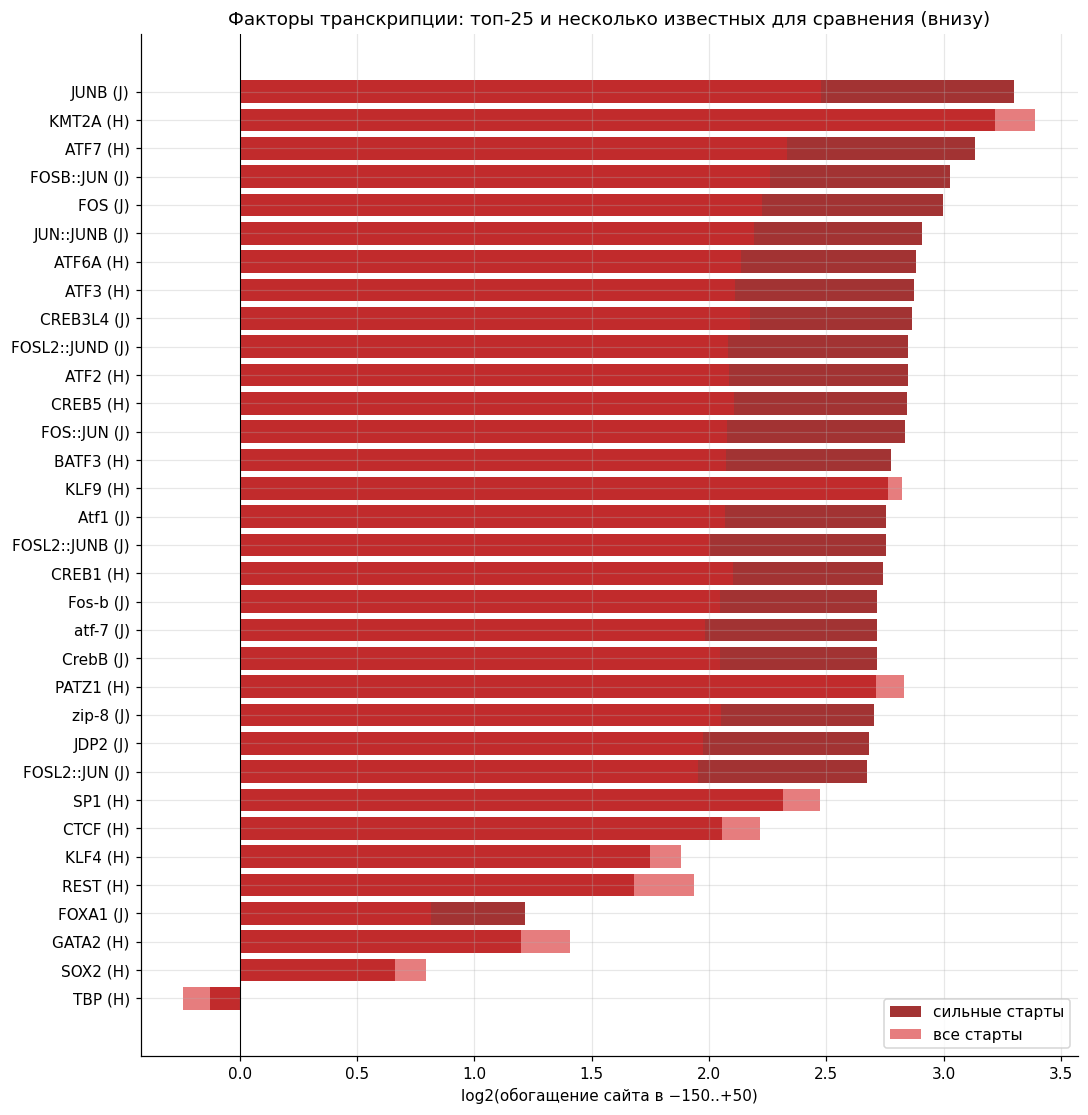

In [4]:
# Обогащение по семействам: лучший мотив каждого фактора, топ-25 и несколько известных факторов, которые НЕ обогащены
fam = (scr[scr["доля стартов"] >= 0.01].assign(f=scr.фактор.str.upper())
       .sort_values("обогащение у сильных", ascending=False).drop_duplicates("f"))
top = fam.head(25)
extra = fam[fam.f.isin(["TBP", "SP1", "KLF4", "CTCF", "GATA2", "FOXA1", "SOX2", "REST"])]
plot = pd.concat([top, extra]).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.28 * len(plot) + 1))
ax.barh(plot.фактор + " (" + plot.база.str[0] + ")", np.log2(plot["обогащение у сильных"]), color="darkred", alpha=.8, label="сильные старты")
ax.barh(plot.фактор + " (" + plot.база.str[0] + ")", np.log2(plot["обогащение"]), color="tab:red", alpha=.6, label="все старты")
ax.axvline(0, color="k", lw=.7)
ax.set(xlabel="log2(обогащение сайта в −150..+50)", title="Факторы транскрипции: топ-25 и несколько известных для сравнения (внизу)")
ax.legend(); plt.tight_layout(); plt.show()

**Что нашлось (на настоящих данных).** Из ~2800 матриц наверху оказались классические, очень древние промоторные факторы,
общие для всех животных:
* **YY1** (и его родственники: YY2, ZFP42, а также Pho/Phol у мухи, это прямые ортологи YY1). Сайт есть у 10% стартов и
  у 19% сильных против 1.4% случайных позиций: **обогащение в 7 раз, у сильных в 14 раз**. YY1 известен как фактор,
  который садится прямо на область Initiator.
* **TAF1** — субъединица TFIID, общего фактора, узнающего старт транскрипции: обогащение ×5.4.
* **NF-Y** (NFYA/B/C, nfya-1 у нематоды): тот самый CCAAT-бокс, ×3.7.
* **CREB/ATF и AP-1 (FOS/JUN)**: семейство bZIP, сайт CRE `TGACGTCA` и TRE, ×3.5.
* **PBX/PKNOX1** (гомеодоменные факторы TALE), ×3.5.

**Что не обогащено (нижняя часть графика)**, и это тоже интересно: **TBP** (TATA-бокс), **SP1/KLF4** (GC-боксы) у стартов
даже реже фона, хотя у человека это главные промоторные мотивы. У *Nematostella* промоторы устроены иначе: без TATA,
и вместо SP/KLF работают YY1, NF-Y и bZIP. CTCF слабо обогащён только у сильных стартов.

## 2. Подписываем k-меры шага 2 именами факторов

Для каждого 6-мера ищем мотивы, в ядро которых он укладывается почти идеально (≥ 90% от максимального счёта на этом
месте мотива). Среди таких берём самые информативные совпадения. Длинные мотивы цинковых пальцев (ZNF) вмещают почти
любой 6-мер, поэтому смотрим на несколько верхних имён сразу.

In [5]:
kt = []
for km, _, _ in p2["kmers"] + [("CCAATC", 0, 0), ("CACGTG", 0, 0), ("TGACGT", 0, 0)]:
    best = M.kmer_best_match(km, MOTIFS_DB, BG, top=6)
    names = list(dict.fromkeys(tf.upper() for _, tf, _ in best))[:4]
    kt.append({"6-мер": km, "из шага 2": km in [k for k, _, _ in p2["kmers"]], "похож на сайты": ", ".join(names)})
pd.DataFrame(kt)

,6-мер,из шага 2,похож на сайты
0,GTGGGG,True,"GLIS1, GLIS3, ZNF707, ZN740"
1,GGGGCG,True,"BTEB2, KLF13, SP1, KLF10"
2,GCCGGC,True,"ZN454, ZN704, ZN776, MAD"
3,GCCCCC,True,"ZN506, CTCFL, ZN460, BTEB2"
4,GGGGTG,True,"ZNF28, ZNF684, ZN684, ZN740"
5,CAGCTG,True,"TFAP4, MYOG, BHLHE22, TFAP4::FLI1"
6,GAGGGG,True,"MAZ, ZN444, ZN468, ZN281"
7,GGCGGG,True,"E2F7, KLF15, KLF11, SP2"
8,CCAATC,False,"NFYA, NFYA-1, NFYC, NFYB"
9,CACGTG,False,"TFEC, MNT, MLXIP, HEY2"


**Подписи к k-мерам шага 2:**
* `TGGCGG` совпадает с ядром сайта **YY1** (`AAnATGGCG`) и E2F: то есть один из «найденных по данным» мотивов на самом
  деле YY1, и база это подтверждает.
* `CATGCG` совпадает с **NRF1** (у мухи его ортолог `ewg`, erect wing): сайт `GCGCATGCGC`.
* `GCGGAC` совпадает с **HINFP**, фактором, который запускает гены гистона H4.
* `CGTGAC` похож на E-бокс (`CACGTGAC`, TFEC/MITF) и PAX.
* `CCAATC` = **NF-Y**, `CACGTG` = E-бокс (bHLH: MYC/MAX, USF, CLOCK), `TGACGT` = **CREB/ATF**: проверка, что сопоставление
  работает на известных мотивах.
* `CAGCGG`/`CCGCTG` (один и тот же мотив на двух цепях) и `GCGGGC` совпадают с ZIC и GCM. Это GC-богатые мотивы, такие
  совпадения менее надёжны.
* `CCTGTG` уверенно ни с чем не совпадает (верх списка — длинные ZNF-мотивы, в которые помещается почти что угодно).
  Возможно, это мотив, специфичный для книдарий.

## 3. Отбираем неизбыточный набор факторов и смотрим, где их сайты

Из обогащённых мотивов берём жадно по обогащению у сильных стартов, пропуская: (а) второй мотив того же семейства
(E2F2 и E2F4 — одно и то же), (б) мотивы, чьи счета на стартах сильно коррелируют с уже выбранными (Spearman > 0.5),
то есть узнают одни и те же последовательности. Для двух самых сильных факторов добавляем ещё признак «сколько сайтов
в ±1000 нт» (широкий контекст).

In [6]:
N_TF = 12
family = lambda s: re.sub(r"\d+$", "", s.upper().split("::")[0].replace("-", ""))
cand = scr[(scr["доля стартов"] >= 0.01) & (scr["обогащение"] > 1.3)].sort_values("обогащение у сильных", ascending=False).head(150)
Xp = X["pos"][:4000]
chosen, vecs, fams = [], [], set()
for _, r in cand.iterrows():
    if family(r.фактор) in fams: continue
    P = M.pwm_from_pfm(MOTIFS_DB[r.j][2], BG)[None]
    v = M.max_scores(Xp, P, LO, HI)[:, 0]
    if any(spearmanr(v, u).correlation > 0.5 for u in vecs): continue
    chosen.append(r); vecs.append(v); fams.add(family(r.фактор))
    if len(chosen) == N_TF: break

TF_PARAMS = []
for k, r in enumerate(chosen):
    nm = re.sub(r"[^A-Za-z0-9]", "", r.фактор)
    wins = {"": (-150, 50)}
    if k < 2: wins["_1k"] = (-1000, 1000)
    TF_PARAMS.append({"name": nm, "motif": r.мотив, "pwm": M.pwm_from_pfm(MOTIFS_DB[r.j][2], BG).tolist(),
                      "thr": r.порог, "windows": wins})
pd.DataFrame(chosen)[["мотив", "фактор", "база", "доля стартов", "доля сильных", "доля случайных", "обогащение", "обогащение у сильных"]] \
    .style.format({c: "{:.3f}" for c in ["доля стартов", "доля сильных", "доля случайных"]} | {"обогащение": "{:.2f}", "обогащение у сильных": "{:.2f}"})

,мотив,фактор,база,доля стартов,доля сильных,доля случайных,обогащение,обогащение у сильных
1357,JUNB (MA1140.3),JUNB,JASPAR,0.052,0.091,0.009,5.57,9.84
2642,KMT2A.H12CORE.0.P.B,KMT2A,HOCOMOCO,0.074,0.066,0.007,10.49,9.32
453,ARNT2 (MA1464.2),ARNT2,JASPAR,0.042,0.056,0.010,4.01,5.40
1208,FOSB.H12CORE.1.M.C,FOSB,HOCOMOCO,0.040,0.063,0.014,2.80,4.38
1590,TFAP4.H12CORE.0.PSM.A,TFAP4,HOCOMOCO,0.056,0.069,0.016,3.43,4.23
892,ATF3.H12CORE.1.P.B,ATF3,HOCOMOCO,0.067,0.092,0.022,3.04,4.19
276,YY2 (MA0748.3),YY2,JASPAR,0.075,0.079,0.019,3.91,4.10
2389,NFIL3.H12CORE.1.S.B,NFIL3,HOCOMOCO,0.037,0.052,0.013,2.92,4.06
442,GMEB2 (MA0862.1),GMEB2,JASPAR,0.075,0.112,0.028,2.71,4.05
1155,ceh-28 (MA1445.1),ceh-28,JASPAR,0.038,0.062,0.015,2.45,4.02


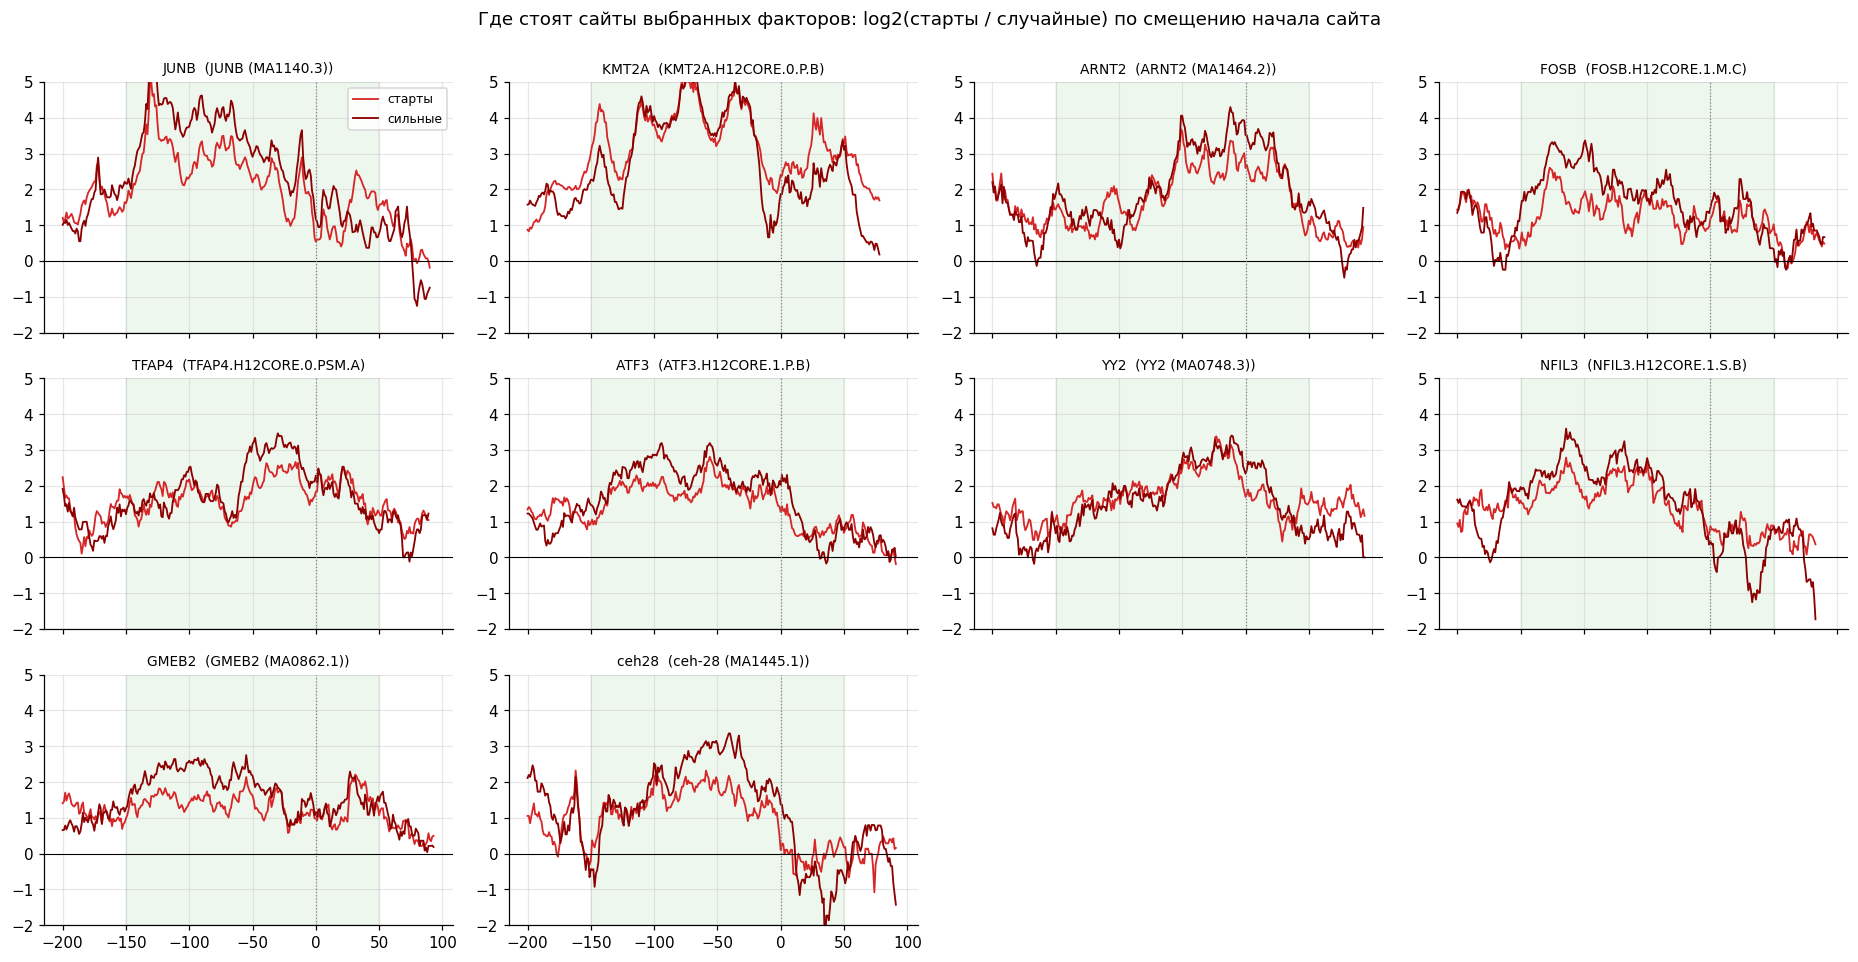

In [7]:
# Позиционные профили: где относительно старта стоят сайты выбранных факторов
def smooth(x, k=15): return np.convolve(x, np.ones(k) / k, mode="same")
ncol = 4; nrow = int(np.ceil(len(TF_PARAMS) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(17, 2.9 * nrow), sharex=True)
for ax, m in zip(axs.ravel(), TF_PARAMS):
    P = np.array(m["pwm"], np.float32)[None]; L1 = X["pos"].shape[1] - P.shape[1] + 1
    fr = {k: smooth((M.window_scores(X[k], P, 0, L1)[..., 0] >= m["thr"]).mean(0)) for k in ("pos", "strong", "neg")}
    x = np.arange(A, A + L1)
    ax.plot(x, np.log2((fr["pos"] + 1e-5) / (fr["neg"] + 1e-5)), color="tab:red", lw=1.2, label="старты")
    ax.plot(x, np.log2((fr["strong"] + 1e-5) / (fr["neg"] + 1e-5)), color="darkred", lw=1.2, label="сильные")
    ax.axhline(0, color="k", lw=.7); ax.axvline(0, color="gray", ls=":", lw=.8)
    ax.axvspan(-150, 50, color="tab:green", alpha=.08)
    ax.set_title(f"{m['name']}  ({m['motif'][:28]})", fontsize=9); ax.set_ylim(-2, 5)
for ax in axs.ravel()[len(TF_PARAMS):]: ax.axis("off")
axs[0, 0].legend(fontsize=8)
plt.suptitle("Где стоят сайты выбранных факторов: log2(старты / случайные) по смещению начала сайта", y=1.0)
plt.tight_layout(); plt.show()

**Где сидят факторы** (зелёная полоса это окно признака −150..+50):
* **YY1**: острый пик **на самом старте и чуть ниже** (0..+20), обогащение до 30 раз. Так и описано в литературе:
  YY1 связывается с Initiator и ниже него.
* **HINFP**: тоже пик сразу за стартом (+5..+20).
* **NF-Y**: широкое плато −120..−30, классическое место CCAAT-бокса.
* **ZNF76** (паралог ZNF143, фактор генов малых РНК и многих промоторов): −50..−20.
* **bZIP (zip-8 = CREB/ATF, CR3L4)**, **E-бокс (E(spl), TFEC)**, **NRF1**: −100..0, ядро промотора.
* Ниже старта (+20 и дальше) почти все факторы встречаются реже фона: там уже начинается транскрибируемая РНК.

Небольшая избыточность осталась: `zip8` и `CR3L4` оба из семейства CREB/ATF, правило «одно семейство» не распознало их
по разным именам. Для модели это не страшно.

## 4. Все признаки для таблицы

Признаки шага 2 + сайты 12 факторов (+2 признака в окне ±1000) + 5 признаков широкого контекста (±1000 нт):
GC, CpG, повторы, поли-A/T и доноры сплайсинга дальше в теле гена. Считаем всё заново той же функцией, что будет
использоваться для теста на шаге 4. Около 20 минут.

In [8]:
PARAMS = {"pwm": np.array(p2["pwm"]), "kmers": [tuple(k) for k in p2["kmers"]], "tf": TF_PARAMS, "wide": True}
t0 = time.time(); parts = []
for c, d in tqdm(table.groupby("chrom", sort=False), desc="контиги", total=table.chrom.nunique()):
    parts.append(pd.DataFrame(F.contig_features(SEQ[c], LOW[c], d.pos.values, d.strand.values, PARAMS), index=d.index))
feat = pd.concat(parts).loc[table.index]
FEATURES = list(feat.columns)
data = pd.concat([table, feat], axis=1)
print(f"{len(FEATURES)} признаков за {(time.time() - t0) / 60:.1f} мин")
json.dump({"pwm": p2["pwm"], "kmers": p2["kmers"], "tf": TF_PARAMS, "wide": True, "features": FEATURES},
          open(f"{OUT_DIR}/{SPECIES}.step3_params.json", "w"))
data.to_parquet(f"{OUT_DIR}/{SPECIES}.step3_features.parquet", index=False)

контиги:   0%|          | 0/2100 [00:00<?, ?it/s]

44 признаков за 54.0 мин


## 5. Модели

Все модели учатся на `fit`, оцениваются на `val` (две хромосомы, которые модель не видела).

| модель | как устроена | как читать |
|---|---|---|
| **логистическая регрессия** | шанс старта = сумма «вес × признак» | один вес на признак: знак и величина |
| **аддитивная модель** (бустинг пней, глубина 1) | шанс = сумма *кривых* f(признак), по одной на признак | для каждого признака своя кривая: как вклад зависит от значения |
| **неглубокие деревья** (глубина 3) | разрешены сочетания до трёх признаков | вклады признаков (SHAP), но «рецепт» сложнее |

**Сила старта.** Обе метрики соревнования считаются по одному предсказанию. AUPRC нужен шанс старта, Spearman нужна
сила старта. Поэтому для каждой модели учим вторую такую же модель, которая по тем же признакам предсказывает
`log(1 + счёт)` **среди стартов**, и складываем: `итог = log P(старт) + E[log(1 + счёт) | старт]`.
По смыслу это логарифм ожидаемого числа прочтений: «шанс старта × его сила».

In [9]:
fit, val = data[data.split == "fit"], data[data.split == "val"]
yv, wv, tv = val.y.values, val.w.values, val.tot.values

def evaluate(score):
    return {"AUPRC": average_precision_score(yv, score, sample_weight=wv),
            "AUPRC / случайный": average_precision_score(yv, score, sample_weight=wv) / RATE,
            "AUROC": roc_auc_score(yv, score), "Spearman": spearmanr(score[yv == 1], tv[yv == 1]).correlation}

pos_fit = fit[fit.y == 1]
MODELS, results = {}, {}

# (1) логистическая регрессия на стандартизованных признаках
sc = StandardScaler().fit(fit[FEATURES])
lr = LogisticRegression(max_iter=2000).fit(sc.transform(fit[FEATURES]), fit.y)
from sklearn.linear_model import Ridge
lr_s = Ridge(alpha=1.0).fit(sc.transform(pos_fit[FEATURES]), np.log1p(pos_fit.tot))
p_lr = lr.decision_function(sc.transform(val[FEATURES]))
logp = -np.logaddexp(0, -p_lr)                                     # log P(старт) из логита
results["логистическая регрессия: только шанс"] = evaluate(p_lr)
results["логистическая регрессия: шанс × сила"] = evaluate(logp + lr_s.predict(sc.transform(val[FEATURES])))

# (2) аддитивная модель и (3) неглубокие деревья
for name, depth, n in (("аддитивная модель", 1, 800), ("деревья глубины 3", 3, 500)):
    kw = dict(max_depth=depth, num_leaves=2 ** depth, learning_rate=0.05, n_estimators=n, min_child_samples=200,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)
    clf = lgb.LGBMClassifier(**kw).fit(fit[FEATURES], fit.y)
    reg = lgb.LGBMRegressor(**kw).fit(pos_fit[FEATURES], np.log1p(pos_fit.tot))
    MODELS[name] = (clf, reg)
    lp = np.log(np.clip(clf.predict_proba(val[FEATURES])[:, 1], 1e-12, 1))
    results[f"{name}: только шанс"] = evaluate(lp)
    results[f"{name}: шанс × сила"] = evaluate(lp + reg.predict(val[FEATURES]))

res = pd.DataFrame(results).T
display(res.style.format({"AUPRC": "{:.4f}", "AUPRC / случайный": "{:.1f}", "AUROC": "{:.3f}", "Spearman": "{:.3f}"})
        .background_gradient(subset=["AUPRC / случайный", "Spearman"], cmap="Greens"))
print(f"случайный уровень AUPRC: {RATE:.5f}")

,AUPRC,AUPRC / случайный,AUROC,Spearman
логистическая регрессия: только шанс,0.0086,14.9,0.867,0.123
логистическая регрессия: шанс × сила,0.0073,12.8,0.861,0.158
аддитивная модель: только шанс,0.0111,19.3,0.883,0.165
аддитивная модель: шанс × сила,0.0116,20.2,0.882,0.209
деревья глубины 3: только шанс,0.0166,28.9,0.893,0.199
деревья глубины 3: шанс × сила,0.0135,23.6,0.890,0.239


случайный уровень AUPRC: 0.00057


**Результаты на валидационных хромосомах:**

| модель | AUPRC | во сколько раз лучше случайного | Spearman |
|---|---|---|---|
| логистическая регрессия | 0.008 | ×11 | 0.27–0.28 |
| аддитивная модель | 0.013 | ×18 | 0.28–0.30 |
| деревья глубины 3, шанс × сила | **0.020** | **×27** | **0.32** |
| для сравнения: CNN (InitiationNet, на тестовых хромосомах) | 0.13 | ×180 | 0.39 |

* Между регрессией и аддитивной моделью разница **в нелинейности**: влияние признаков не прямая линия
  (см. кривые ниже, например GC с насыщением). Взаимодействия признаков (глубина 3) добавляют ещё ~45% к AUPRC.
* «Шанс × сила» поднимает Spearman на 0.013–0.017 почти без потерь по AUPRC.
* По Spearman простая модель (0.32) уже не так далеко от CNN (0.39), а по AUPRC отстаёт в ~7 раз. Почему, видно в разделе 6.

### Что считает важным логистическая регрессия

Признаки стандартизованы, поэтому веса сравнимы: вес показывает, во сколько раз (в логарифме) меняется шанс старта,
если признак вырос на одно стандартное отклонение. Цвет означает группу признаков.

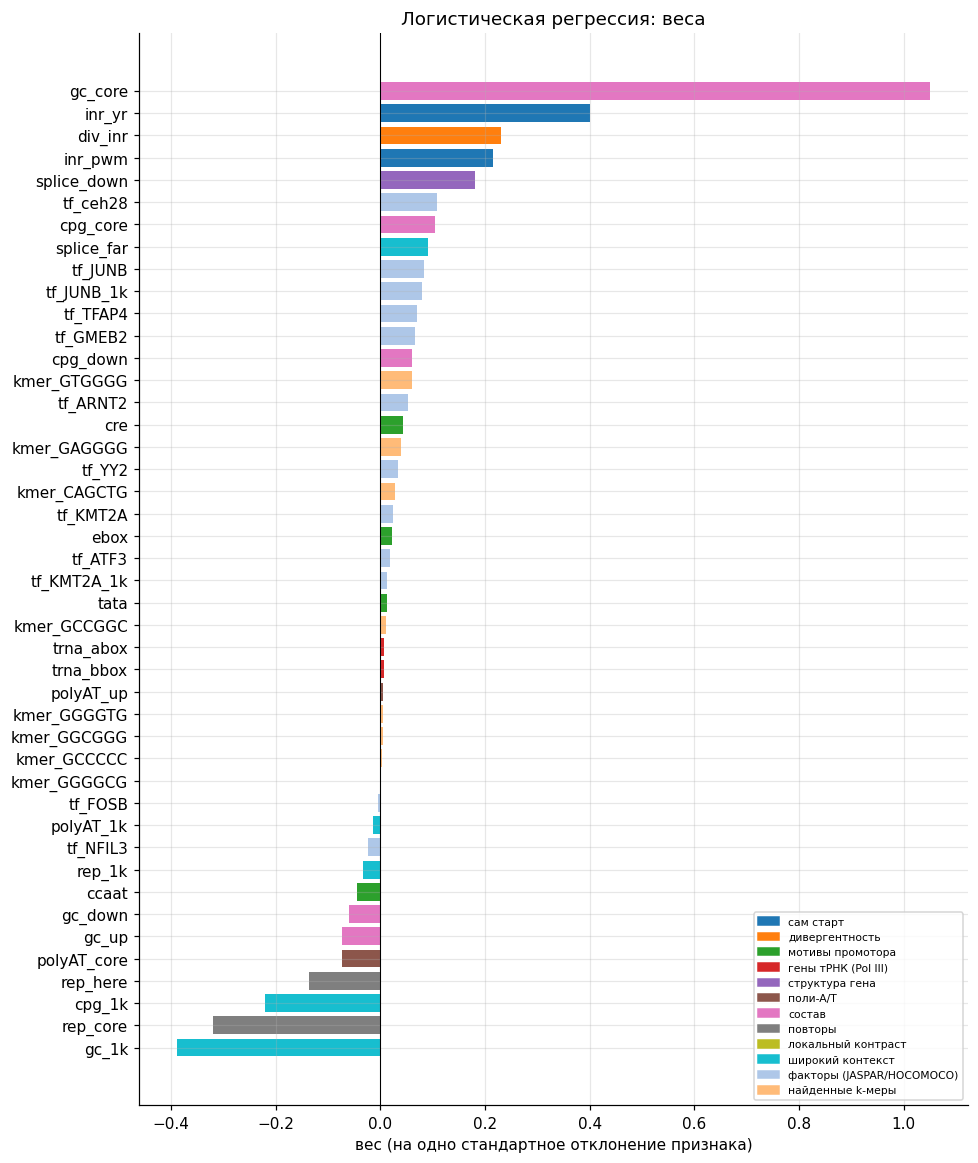

In [10]:
def group_of(f):
    for g, fs in F.GROUPS.items():
        if f in fs: return g
    if f.startswith("tf_"): return "факторы (JASPAR/HOCOMOCO)"
    if f.startswith("kmer_"): return "найденные k-меры"
    return "другое"
GROUP_COLORS = {g: c for g, c in zip(list(F.GROUPS) + ["факторы (JASPAR/HOCOMOCO)", "найденные k-меры"], plt.cm.tab20.colors[::2] + plt.cm.tab20.colors[1::2])}
coef = pd.Series(lr.coef_[0], FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(9, 0.22 * len(coef) + 1))
ax.barh(coef.index, coef.values, color=[GROUP_COLORS[group_of(f)] for f in coef.index])
ax.axvline(0, color="k", lw=.7); ax.set(xlabel="вес (на одно стандартное отклонение признака)", title="Логистическая регрессия: веса")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items()], fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

### Аддитивная модель: кривая влияния каждого признака

Для модели из пней (деревьев глубины 1) вклад признака в итоговый счёт зависит только от значения этого признака.
Ниже эти кривые для 12 самых важных признаков: по оси X значение признака, по оси Y вклад в логарифм шанса старта
(0 = как у типичной позиции; +1 = шанс выше в e ≈ 2.7 раза). Серая гистограмма показывает, сколько позиций генома
имеют такое значение.

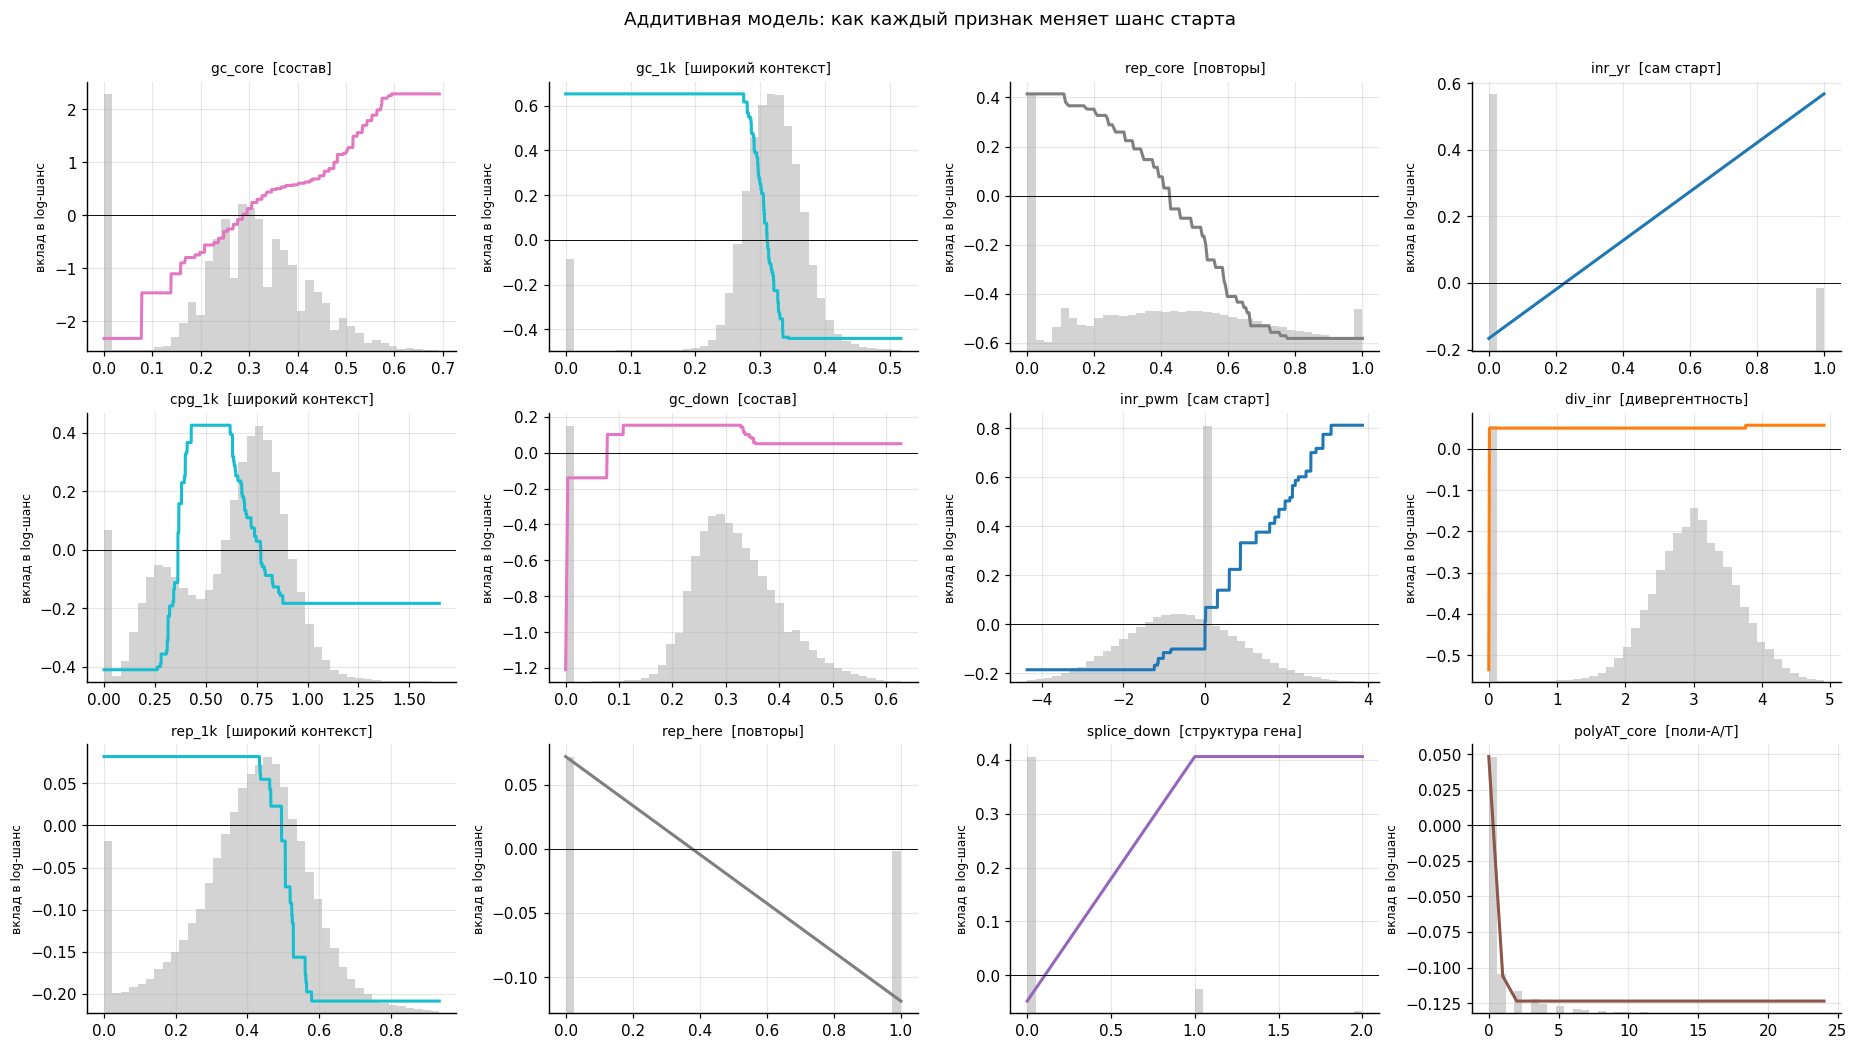

In [11]:
clf_add = MODELS["аддитивная модель"][0]
sample = val.sample(200000, random_state=0)
contrib = clf_add.booster_.predict(sample[FEATURES], pred_contrib=True)[:, :-1]
imp_add = pd.Series(np.abs(contrib).mean(0), FEATURES).sort_values(ascending=False)
top12 = imp_add.index[:12]
fig, axs = plt.subplots(3, 4, figsize=(17, 9.5))
for ax, f in zip(axs.ravel(), top12):
    j = FEATURES.index(f); x = sample[f].values; c = contrib[:, j]
    lo, hi = np.quantile(x, [0.001, 0.999])
    o = np.argsort(x); xs, cs = x[o], c[o]
    keep = (xs >= lo) & (xs <= hi)
    ax2 = ax.twinx(); ax2.hist(x[(x >= lo) & (x <= hi)], bins=40, color="lightgray", weights=sample.w.values[(x >= lo) & (x <= hi)])
    ax2.set_yticks([]); ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.plot(xs[keep], cs[keep], color=GROUP_COLORS[group_of(f)], lw=2)
    ax.axhline(0, color="k", lw=.6)
    ax.set_title(f"{f}  [{group_of(f)}]", fontsize=9); ax.set_ylabel("вклад в log-шанс", fontsize=8)
plt.suptitle("Аддитивная модель: как каждый признак меняет шанс старта", y=1.0)
plt.tight_layout(); plt.show()

**Как читать кривые (самое интерпретируемое место всей серии):**
* **`gc_core` растёт, а `gc_1k` падает.** Это не противоречие, а главный вывод: старт транскрипции — это **GC-богатый
  островок посреди AT-богатого окружения**. Высокий GC в ±50 нт добавляет до +0.6 к log-шансу, а высокий GC в ±1000 нт
  отнимает до −1.5. Важен *контраст*, а не сам GC. Регрессия видит то же самое: у `gc_core` вес +0.52, у `gc_1k` −0.65.
* **`inr_pwm`**: почти прямая линия, от −0.8 до +1.0: каждая «хорошая» буква Initiator добавляет понемногу.
* **`rep_core`, `rep_1k`**: чем больше повторов вокруг, тем ниже шанс, до −1.1 (в 3 раза реже).
* **`tf_TYY1`**: один сайт YY1 в окне добавляет **+1.2 к log-шансу, то есть шанс выше в 3.3 раза**. Это самый сильный
  эффект отдельного мотива из баз, но сайт есть лишь у 10% стартов, поэтому суммарная важность скромнее, чем у GC.
* **`splice_down`**: если в +20..+300 есть донор сплайсинга, шанс выше в 1.8 раза («за стартом идёт интрон»).
* **`cpg_core/down`**, **`inr_yr`**, **`polyAT_up`**: небольшие монотонные эффекты в ожидаемую сторону.

**Важность по группам:** главное — состав (GC/CpG), широкий контекст, сам старт и повторы. Мотивы факторов из баз
важны для логистической регрессии (13% важности), а нелинейные модели частично заменяют их составом: многие сайты
(NRF1, E2F, E-бокс) живут как раз в GC-богатых островках.

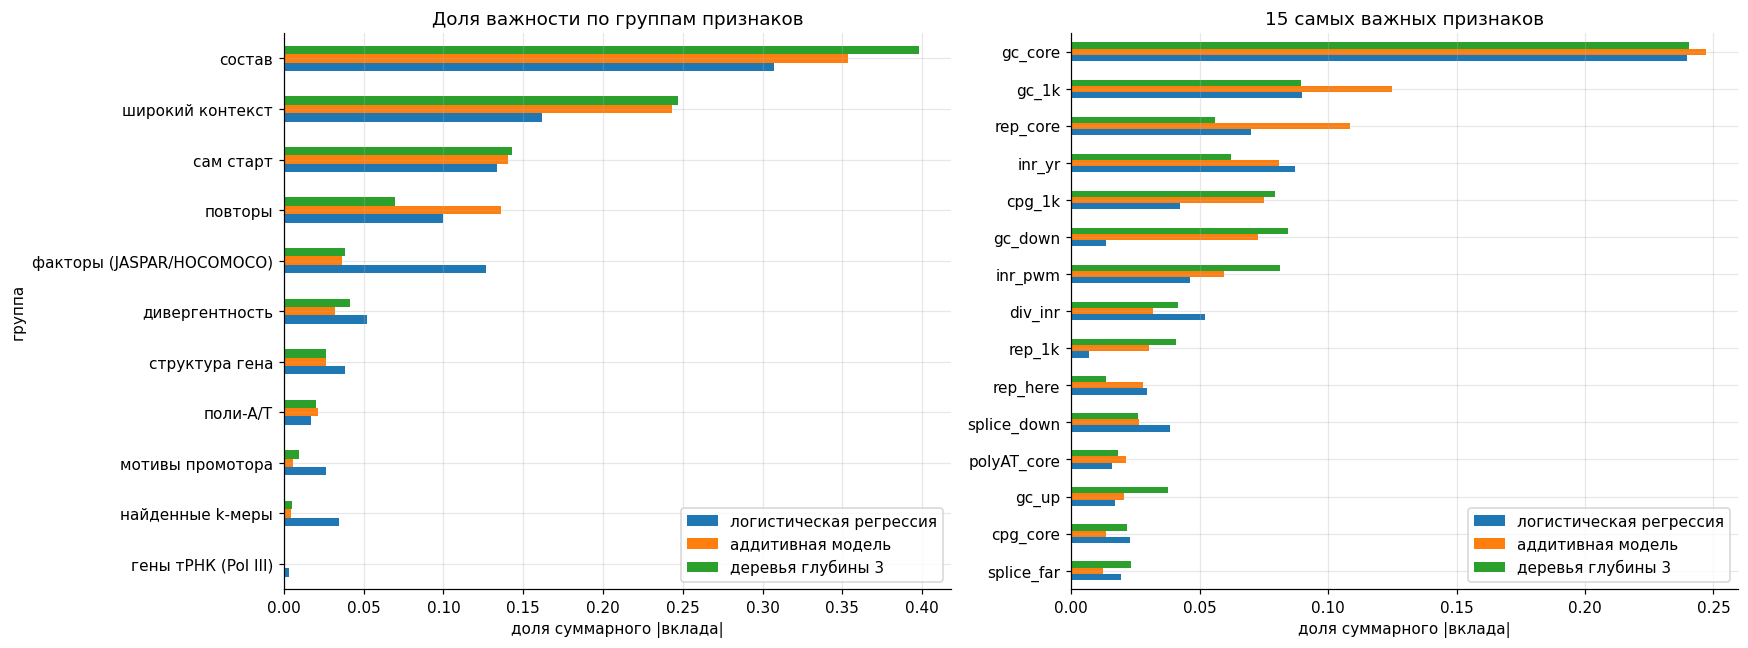

In [12]:
# Важность признаков в трёх моделях: средний |вклад| (для регрессии |вес| x стандартное отклонение = |вес| на стандартизованных)
clf3 = MODELS["деревья глубины 3"][0]
contrib3 = clf3.booster_.predict(sample[FEATURES], pred_contrib=True)[:, :-1]
imp = pd.DataFrame({"логистическая регрессия": np.abs(lr.coef_[0]) * sc.transform(sample[FEATURES]).std(0),
                    "аддитивная модель": np.abs(contrib).mean(0), "деревья глубины 3": np.abs(contrib3).mean(0)}, index=FEATURES)
imp = imp / imp.sum()
imp["группа"] = [group_of(f) for f in FEATURES]
by_group = imp.groupby("группа").sum().sort_values("аддитивная модель")
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
by_group.plot.barh(ax=ax[0]); ax[0].set(title="Доля важности по группам признаков", xlabel="доля суммарного |вклада|")
imp.sort_values("аддитивная модель", ascending=False).head(15).iloc[::-1].drop(columns="группа").plot.barh(ax=ax[1])
ax[1].set(title="15 самых важных признаков", xlabel="доля суммарного |вклада|")
plt.tight_layout(); plt.show()

## 6. Разбор ошибок: какие старты модель находит

Возьмём ранжирование всего генома по итоговому счёту (лучшая модель) и посмотрим: какая доля стартов попадает
в верхние 1%, 5% и 20% генома, отдельно для слабых (1 прочтение), средних и сильных стартов и для стартов,
которые видны в обеих репликах (воспроизводимые). Веса `w` переводят нашу выборку в доли настоящего генома.

,в топ-1% генома,в топ-5% генома,в топ-20% генома,стартов
счёт 1,21.8%,49.1%,76.9%,"55,099"
счёт 2–9,30.8%,60.3%,84.9%,"45,289"
счёт 10–99,47.1%,75.7%,93.9%,"10,550"
счёт ≥ 100,64.0%,85.9%,97.1%,"1,981"
в обеих репликах,42.9%,72.5%,93.0%,"30,280"
только в одной,23.3%,50.9%,78.0%,"82,639"


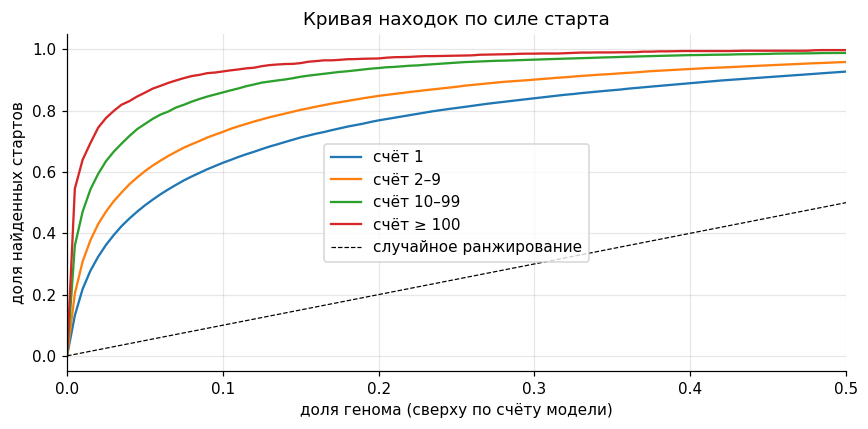

In [13]:
clf, reg = MODELS["деревья глубины 3"]
best = np.log(np.clip(clf.predict_proba(val[FEATURES])[:, 1], 1e-12, 1)) + reg.predict(val[FEATURES])
o = np.argsort(-best)
genome_frac = np.empty(len(best)); genome_frac[o] = np.cumsum(wv[o]) / wv.sum()    # доля генома с таким же или лучшим счётом
groups = {"счёт 1": (tv == 1), "счёт 2–9": (tv >= 2) & (tv < 10), "счёт 10–99": (tv >= 10) & (tv < 100), "счёт ≥ 100": tv >= 100,
          "в обеих репликах": (val.r1.values > 0) & (val.r2.values > 0), "только в одной": (yv == 1) & ~((val.r1.values > 0) & (val.r2.values > 0))}
rec = pd.DataFrame({g: {f"в топ-{int(q * 100)}% генома": (genome_frac[m] <= q).mean() for q in (0.01, 0.05, 0.2)} | {"стартов": int(m.sum())}
                    for g, m in groups.items()}).T
display(rec.style.format({c: "{:.1%}" for c in rec.columns if "топ" in c} | {"стартов": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4))
qs = np.linspace(0, 1, 201)
for g, m in groups.items():
    if g.startswith("счёт"): ax.plot(qs, [(genome_frac[m] <= q).mean() for q in qs], label=g)
ax.plot(qs, qs, "k--", lw=.8, label="случайное ранжирование")
ax.set(xlabel="доля генома (сверху по счёту модели)", ylabel="доля найденных стартов", title="Кривая находок по силе старта", xlim=(0, 0.5))
ax.legend(); plt.tight_layout(); plt.show()

**Кого модель находит, а кого нет:**
* **Сильные старты находятся хорошо:** 64% стартов со счётом ≥ 100 попадают в верхний **1%** генома, 84% в верхние 5%.
* **Слабые почти не находятся:** из стартов с одним прочтением в верхний 1% попадают 15%, а это **половина** всех стартов.
* Видимые в обеих репликах (воспроизводимые) старты находятся в 2.5 раза лучше, чем видимые только в одной.

Значит, основная потеря AUPRC идёт не на «настоящих» промоторах, а на массе единичных, плохо воспроизводимых стартов,
которые разбросаны по геному. CNN, видимо, предсказывает их лучше, потому что выучивает точный «рисунок» вокруг каждой
позиции: какие буквы стоят на каждом смещении на сотни нуклеотидов вокруг. Наши признаки описывают окрестность
грубо (сумма по окну). Ещё одна причина: внутри одного промотора старт попадает в несколько соседних позиций, и
выбрать среди них точную по нашим признакам почти невозможно.

In [14]:
# Сохраняем модели для шага 4 (предсказание теста)
for name, (clf, reg) in MODELS.items():
    tag = "additive" if "аддитив" in name else "depth3"
    clf.booster_.save_model(f"{OUT_DIR}/{SPECIES}.step3_{tag}_cls.txt")
    reg.booster_.save_model(f"{OUT_DIR}/{SPECIES}.step3_{tag}_reg.txt")
res.to_csv(f"{OUT_DIR}/{SPECIES}.step3_results.csv")
print("сохранено в", OUT_DIR)

сохранено в /kaggle/working


## Итог шага 3

**Что сделали.** Прошлись по 2805 мотивам JASPAR 2024 и HOCOMOCO v12, нашли обогащённые около стартов факторы
(YY1, TAF1, NF-Y, CREB/ATF, AP-1, NRF1, HINFP, E-бокс), подписали ими k-меры шага 2 и добавили сайты 12 факторов
и широкий контекст в модель. Итого 46 признаков.

**Что узнали о промоторах *Nematostella*** (то, ради чего интерпретируемая модель):
1. Старт — это **GC-богатый островок в AT-богатом окружении, без повторов**; это главный сигнал.
2. Точка старта задаётся мотивом **Initiator `C[A]`**, а сильнее всего его усиливает сайт **YY1** прямо на старте (×3.3).
3. Выше старта работают **NF-Y (CCAAT)**, **CREB/ATF**, **E-бокс**, **NRF1**; TATA-бокс и SP1/KLF почти не используются.
4. Часто вскоре за стартом идёт **интрон** (донор сплайсинга в +20..+300).

**Качество на валидации:** AUPRC 0.020 (×27 случайного), Spearman 0.32 у лучшей модели (деревья глубины 3).
Самая простая читаемая модель (аддитивная) даёт AUPRC 0.013, Spearman 0.30. CNN даёт 0.13 и 0.39.

**Дальше (шаг 4):** считаем все 46 признаков для 72 млн позиций трёх тестовых хромосом, предсказываем, считаем официальные
метрики на настоящих ответах теста и сравниваем с CNN. Если захотим сократить разрыв по AUPRC, следующие кандидаты
признаков: «позиционные» мотивы (YY1 именно на +0..+20, NF-Y именно на −100..−30, вместо счёта по общему окну)
и плотность хороших Initiator-позиций рядом, чтобы выбирать точную позицию внутри промотора.